make_moons dataset generated successfully!

Shape of data: (300, 2)

First 5 rows:
    Feature_1  Feature_2
0   0.622519  -0.372101
1   1.904269  -0.136303
2  -0.069431   0.456117
3   0.933899   0.237483
4   1.180360  -0.490847

Missing values per column:
 Feature_1    0
Feature_2    0
dtype: int64

Dataset description:
         Feature_1   Feature_2
count  300.000000  300.000000
mean     0.500413    0.253196
std      0.871355    0.496069
min     -1.104663   -0.563235
25%     -0.063124   -0.197303
50%      0.485312    0.248550
75%      1.047578    0.713130
max      2.131198    1.107772


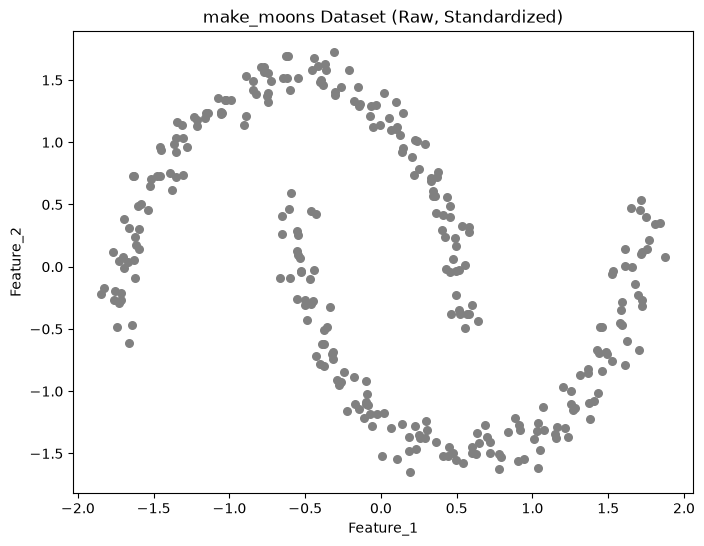

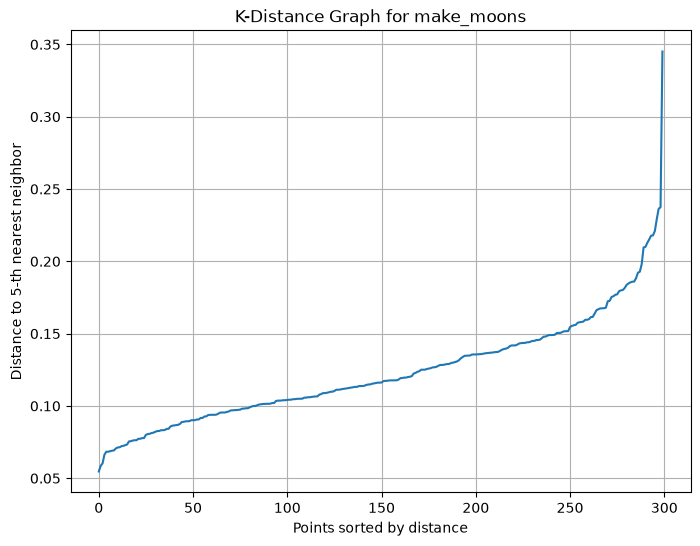


Cluster distribution (DBSCAN):
 Cluster
 0    150
 1    148
-1      2
Name: count, dtype: int64

DBSCAN found 2 clusters and 2 noise points


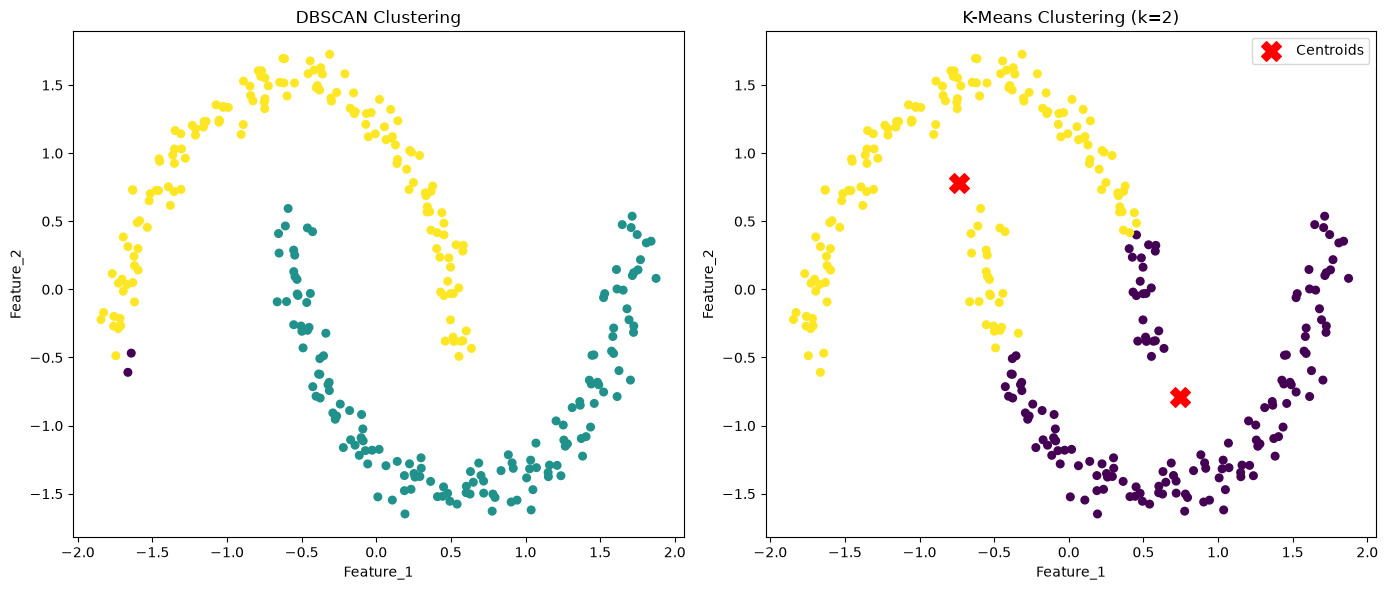


Mean feature values per cluster:
          Feature_1  Feature_2
Cluster                      
0         1.004969  -0.128736
1         0.008472   0.643892


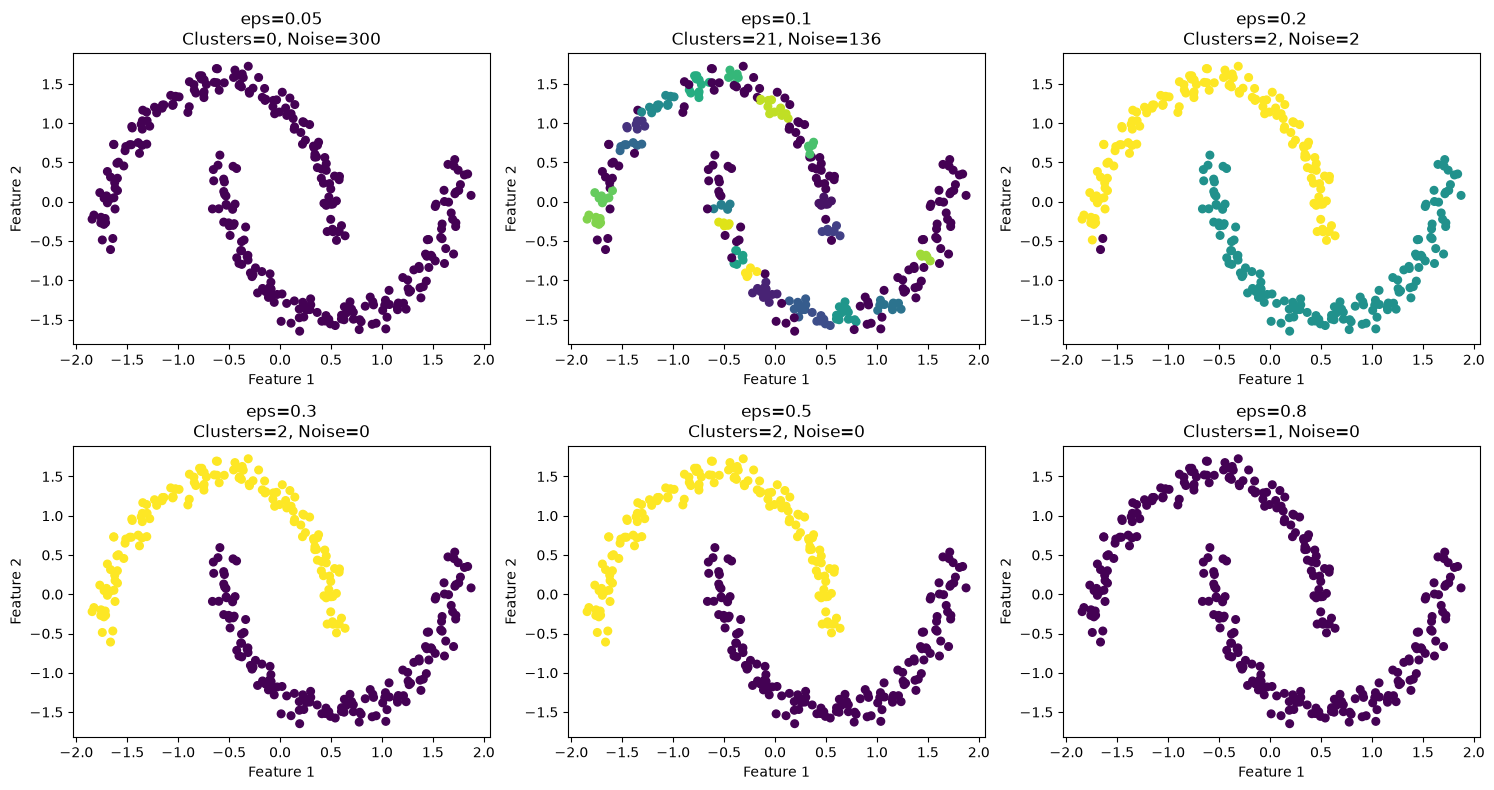

In [ ]:

import pandas as pd
import numpy as np
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN, KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt

X_moons, y_moons_true = make_moons(
    n_samples=300,
    noise=0.05,
    random_state=42
)
data_moons = pd.DataFrame(
    X_moons,
    columns=["Feature_1", "Feature_2"]
)

print("make_moons dataset generated successfully!")
print("\nShape of data:", data_moons.shape)
print("\nFirst 5 rows:\n", data_moons.head())
print("\nMissing values per column:\n", data_moons.isna().sum())
print("\nDataset description:\n", data_moons.describe())

scaler = StandardScaler()
data_moons_scaled = pd.DataFrame(
    scaler.fit_transform(data_moons),
    columns=data_moons.columns
)

plt.figure(figsize=(8, 6))
plt.scatter(
    data_moons_scaled["Feature_1"],
    data_moons_scaled["Feature_2"],
    color="gray",
    s=30
)
plt.title("make_moons Dataset (Raw, Standardized)")
plt.xlabel("Feature_1")
plt.ylabel("Feature_2")
plt.show()

min_samples = 5

neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(data_moons_scaled)
distances, indices = neighbors_fit.kneighbors(data_moons_scaled)
k_distances = np.sort(distances[:, min_samples - 1])


plt.figure(figsize=(8, 6))
plt.plot(k_distances)
plt.title("K-Distance Graph for make_moons")
plt.xlabel("Points sorted by distance")
plt.ylabel(f"Distance to {min_samples}-th nearest neighbor")
plt.grid(True)
plt.show()


eps_value = 0.2
dbscan = DBSCAN(
    eps=eps_value,
    min_samples=min_samples
)
dbscan_labels = dbscan.fit_predict(data_moons_scaled)
data_moons["Cluster"] = dbscan_labels
print(
    "\nCluster distribution (DBSCAN):\n",
    data_moons["Cluster"].value_counts()
    )
n_clusters_dbscan = len(set(dbscan_labels)) - (
    1 if -1 in dbscan_labels else 0)
n_noise_dbscan = list(dbscan_labels).count(-1)
print(
    f"\nDBSCAN found {n_clusters_dbscan} clusters "
    f"and {n_noise_dbscan} noise points"
)

kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)
kmeans_labels = kmeans.fit_predict(data_moons_scaled)


fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# DBSCAN Graph
axes[0].scatter(
    data_moons_scaled["Feature_1"],
    data_moons_scaled["Feature_2"],
    c=dbscan_labels,
    cmap="viridis",
    s=30
)

axes[0].set_title("DBSCAN Clustering")

axes[0].set_xlabel("Feature_1")
axes[0].set_ylabel("Feature_2")


# K-Means Graph
axes[1].scatter(
    data_moons_scaled["Feature_1"],
    data_moons_scaled["Feature_2"],
    c=kmeans_labels,
    cmap="viridis",
    s=30
)

axes[1].scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    c="red",
    marker="X",
    s=200,
    label="Centroids"
)

axes[1].set_title("K-Means Clustering (k=2)")
axes[1].set_xlabel("Feature_1")
axes[1].set_ylabel("Feature_2")
axes[1].legend()

plt.tight_layout()
plt.show()

cluster_summary = data_moons[
    data_moons["Cluster"] != -1
].groupby("Cluster").mean()

if cluster_summary.empty:
    print(
        "\nNo valid clusters found. "
        "Try adjusting DBSCAN parameters (eps, min_samples)."
    )
else:
    print(
        "\nMean feature values per cluster:\n",
        cluster_summary
    )

eps_values_to_try = [0.05, 0.1, 0.2, 0.3, 0.5, 0.8]

plt.figure(figsize=(15, 8))

for i, eps_try in enumerate(eps_values_to_try, 1):

    db = DBSCAN(
        eps=eps_try,
        min_samples=min_samples
    )

    labels = db.fit_predict(data_moons_scaled)

    n_clust = len(set(labels)) - (
        1 if -1 in labels else 0
    )

    n_noise = list(labels).count(-1)

    plt.subplot(2, 3, i)

    plt.scatter(
        data_moons_scaled["Feature_1"],
        data_moons_scaled["Feature_2"],
        c=labels,
        cmap="viridis",
        s=30
    )

    plt.title(
        f"eps={eps_try}\nClusters={n_clust}, Noise={n_noise}"
    )

    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")

plt.tight_layout()
plt.show()
